初期化

In [8]:
import numpy as np
import matplotlib
import matplotlib.pyplot as plt

print(np.__version__)
print(matplotlib.__version__)


2.2.6
3.10.8


出力設定

In [9]:
# 画像出力先
out_path = "./img"

変数設定

In [25]:
# --- 設定変数 (変更可能) ---
NUM_NODES = 20           # ノード数
DATA_BITS = 96         # 1パケットあたりのデータビット数
BITS_PER_SLOT = 96     # 1スロットあたりの最大容量（bit）
NFC_SPEED_BPS = 26480   # NFCの通信速度 (424kbps = 424,000 bps)
# 【計算方法】1スロットの時間(s) = 送信ビット数 / 通信速度(bps)
SLOT_DURATION = DATA_BITS / NFC_SPEED_BPS
SLOT_RANGE = range(1, 257, 1)  # スロット数の範囲
TRIALS = 10000

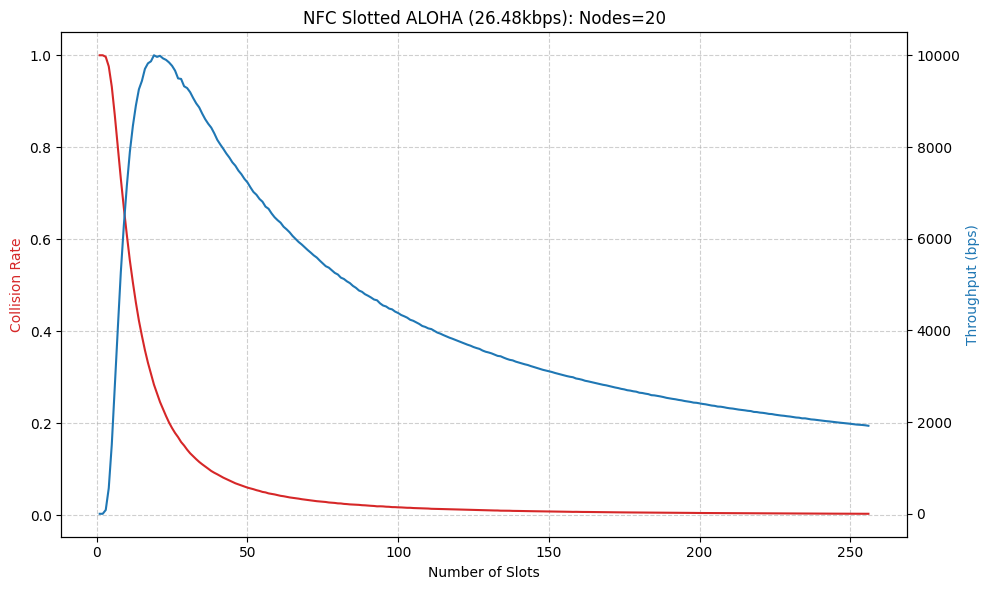

In [26]:
# このプログラムは、スロット数を変化させながら、Slotted Alohaの衝突率とスループットをシミュレーションするものです。

def simulate_slotted_aloha_matrix():
    collision_rates = []
    throughputs = []

    for num_slots in SLOT_RANGE:
        total_collisions = 0
        total_success_slots = 0
        
        for _ in range(TRIALS):
            slot_matrix = np.zeros((NUM_NODES, num_slots))
            choices = np.random.randint(0, num_slots, NUM_NODES)
            slot_matrix[np.arange(NUM_NODES), choices] = 1
            
            pulses_per_slot = np.sum(slot_matrix, axis=0)
            total_collisions += np.sum(pulses_per_slot > 1)
            total_success_slots += np.sum(pulses_per_slot == 1)

        # --- スループット計算の切り替え箇所 ---
        
        # A. ネットワーク全体の合計スループット (bps)
        # (成功数 * ビット数) / (全スロット数 * 1スロットの秒数 * 試行回数)
        avg_throughput = (total_success_slots * DATA_BITS) / (num_slots * SLOT_DURATION * TRIALS)
        
        # B. 1ノードあたりの平均スループット (bps)
        # 上記の値をノード数で割る場合は下の行のコメントアウトを外す
        # avg_throughput = ((total_success_slots * DATA_BITS) / (num_slots * SLOT_DURATION * TRIALS)) / NUM_NODES
        
        collision_rates.append(total_collisions / (num_slots * TRIALS))
        throughputs.append(avg_throughput)
        
    return list(SLOT_RANGE), collision_rates, throughputs

# --- プロット処理 ---
slots, coll_rates, thr_put = simulate_slotted_aloha_matrix()
fig, ax1 = plt.subplots(figsize=(10, 6))

ax1.set_xlabel('Number of Slots')
ax1.set_ylabel('Collision Rate', color='tab:red')
ax1.plot(slots, coll_rates, color='tab:red')
ax1.grid(True, linestyle='--', alpha=0.6)

ax2 = ax1.twinx()
ax2.set_ylabel('Throughput (bps)', color='tab:blue')
ax2.plot(slots, thr_put, color='tab:blue')

plt.title(f'NFC Slotted ALOHA ({NFC_SPEED_BPS/1000}kbps): Nodes={NUM_NODES}')
fig.tight_layout()
plt.savefig(f'{out_path}/slotted_aloha_typeV_tag20_26480bps.pdf', format='pdf', bbox_inches='tight')
plt.show()